# Plotting figures

In [1]:
import os

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.ticker as ticker
import numpy as np

%matplotlib inline

### A small colour palette (chosen with colour blindness in mind)

In [1]:
str([1,2])

'[1, 2]'

In [2]:

blue_shade_1 = '#0072B2'
blue_shade_1_light = '#5EC1F9'

blue_shade_2 = '#56B5E9'
blue_shade_2_light = '#C0E8FF'

orange_shade_1 = '#D55E00'
orange_shade_1_light = '#F1964E'

orange_shade_2 = '#E69F00'
orange_shade_2_light = '#FFE7B4'

green_shade_1 = '#009E73'
green_shade_1_light = '#38C39D'

green_shade_2 = '#52C9A8'
green_shade_2_light = '#B3EBDC'

light_grey = '#EDEDED'

In [3]:
# @title Figure settings

SMALLER_SIZE = 17   #@param{type:'number'}
SMALL_SIZE = 19     #@param{type:'number'}
MEDIUM_SIZE = 22    #@param{type:'number'}
BIGGER_SIZE = 26    #@param{type:'number'}

MARKER_SIZE = 8
LINEWIDTH = 1.5     #@param{type:'number'}
MAJOR_TICK_SIZE = 6 #@param{type:'number'}
MINOR_TICK_SIZE = 3 #@param{type:'number'}
MAJOR_TICK_PAD = 2  #@param{type:'number'}

rc_params = {'axes.linewidth': LINEWIDTH,

             'xtick.major.size': MAJOR_TICK_SIZE,
             'xtick.minor.size': MINOR_TICK_SIZE,
             'xtick.major.width': LINEWIDTH,
             'xtick.minor.width': LINEWIDTH,
             'xtick.major.pad': MAJOR_TICK_PAD,
             'xtick.direction': 'inout',
             'xtick.labelsize': SMALL_SIZE,     # font size of the tick labels

             'ytick.major.size': MAJOR_TICK_SIZE,
             'ytick.minor.size': MINOR_TICK_SIZE,
             'ytick.major.width': LINEWIDTH,
             'ytick.minor.width': LINEWIDTH,
             'ytick.major.pad': MAJOR_TICK_PAD,
             'ytick.direction': 'inout',
             'ytick.labelsize': SMALL_SIZE,     # font size of the tick labels

             'errorbar.capsize': 0,

             'axes.labelpad': 1.5,
             'axes.titlesize': MEDIUM_SIZE,     # font size of the axes title
             'axes.labelsize': MEDIUM_SIZE,      # font size of the x and y labels

            #  'font.family': 'sans-serif',
            #  'font.sans-serif': 'Roboto',
             'font.weight': 'normal',
             'font.size': SMALL_SIZE,           # controls default text sizes

             'grid.color': light_grey,
             'grid.linewidth': LINEWIDTH,

             'hatch.linewidth': LINEWIDTH-0.3,

             'legend.frameon': False,           # don't show a box around the legend
             'legend.fontsize': SMALLER_SIZE,     # legend font size
             'legend.labelspacing': 0.35,
             'legend.handlelength': 0,
             'legend.handletextpad': 1,

             'figure.titlesize': BIGGER_SIZE,   # font size of the figure title
}

matplotlib.rcParams.update(rc_params)

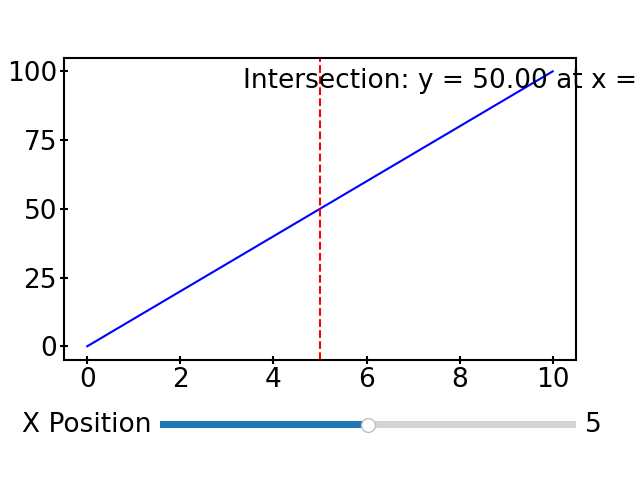

In [4]:
%matplotlib widget

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.widgets import Slider

# Example data
x = np.linspace(0, 10, 100)
y = 10 * x  # Linear function, as an example

# Create the figure and axis
fig, ax = plt.subplots()
plt.subplots_adjust(left=0.1, bottom=0.25)  # Leave space for the slider

# Plot the main line
line, = ax.plot(x, y, label='y = 10 * x', color='b')

# Initial vertical line at x = 5
vline = ax.axvline(x=5, color='r', linestyle='--')

# Create a text annotation for intersection point
intersection_text = ax.text(0.5, 0.5, '', transform=ax.transAxes, ha='center')

# Function to calculate y-value at the intersection with the vertical line
def update_intersection(x_val):
    y_val = np.interp(x_val, x, y)  # Get the y-value at the given x using interpolation
    vline.set_data([x_val, x_val], [0, max(y)])  # Move the vertical line as a sequence
    intersection_text.set_text(f'Intersection: y = {y_val:.2f} at x = {x_val:.2f}')
    intersection_text.set_position((0.8, 0.9))  # Set position of text
    fig.canvas.draw_idle()

# Slider for controlling the vertical line position
ax_slider = plt.axes([0.25, 0.1, 0.65, 0.03], facecolor='lightgoldenrodyellow')  # Slider axis
x_slider = Slider(ax_slider, 'X Position', 0, 10, valinit=5)

# Update the plot when the slider is changed
x_slider.on_changed(update_intersection)

# Initialize the plot with the starting values
update_intersection(5)

# Show the plot
plt.show()


In [9]:
%matplotlib widget


In [ ]:
# @title Plot some data

# For plots that span one column, set the width parameter of `figsize` to 10.
# If it spans two columns, set it to 20.5. Adjust the height according to
# preference. Aspect ratio for a single plot of (1.6 : 1) is nice.
fig = plt.figure(figsize=(10, 6.5))
ax = fig.add_subplot(111)

def expected_length(acceptance_rate, speculation_length=6):
    return (1-acceptance_rate**(speculation_length+1))/(1-acceptance_rate)
  
def expected_speedup(acceptance_rate, draft_speedup, speculation_length=6):
    return expected_length(acceptance_rate, speculation_length)/(speculation_length/draft_speedup+1)

def required_draft_speedup(theoretical_speedup, acceptance_rate, speculation_length=6):
    return speculation_length/((expected_length(acceptance_rate, speculation_length)/theoretical_speedup)-1)

def clamp(a):
    if a<0:
      return 100
    return min(100, a)

acceptance_rate = np.array([i/100 for i in range(1,99)])
y1_2x = np.array([clamp(required_draft_speedup(1.2, i)) for i in acceptance_rate])
y1_5x = np.array([clamp(required_draft_speedup(1.5, i)) for i in acceptance_rate])
y1_7x = np.array([clamp(required_draft_speedup(1.7, i)) for i in acceptance_rate])
y2x = np.array([clamp(required_draft_speedup(2, i)) for i in acceptance_rate])
y2_2x = np.array([clamp(required_draft_speedup(2.2, i)) for i in acceptance_rate])


ax.plot(acceptance_rate[y1_2x<100], y1_2x[y1_2x<100], color=blue_shade_1, lw=LINEWIDTH, label='Some function')
ax.plot(acceptance_rate[y1_5x<100], y1_5x[y1_5x<100], color=blue_shade_1, lw=LINEWIDTH, label='Some function')
ax.plot(acceptance_rate[y1_7x<100], y2x[y1_7x<100], color=blue_shade_1, lw=LINEWIDTH, label='Some function')
ax.plot(acceptance_rate[y2x<100], y2x[y2x<100], color=blue_shade_1, lw=LINEWIDTH, label='Some function')

# ax.plot(acceptance_rate[y2x>=100], y2x[y2x>=100], color=blue_shade_1, lw=LINEWIDTH, linestyle='dashed')



# def my_func(x_vals):
#   """Some random numeric function."""
#   return 4*np.sin(20*x_vals) * np.exp(-x_vals)

# # Generate some data
# time = np.linspace(0, 2, 300)
# y_vals = my_func(time)

# time_sparse = np.linspace(0, 2, 25)
# y_vals_sparse = my_func(time_sparse)
# y_errors_sparse = 0.4*np.ones(len(time_sparse))

# # Plot dense points as a line
# ax.plot(time, y_vals, color=blue_shade_1, lw=LINEWIDTH, label='Some function')

# # Plot symbols with rounded off error bars. Yes, I know the rounded caps sound
# # silly, but it actually does look more professional.
# _, _, barlinecols = ax.errorbar(time_sparse,
#                                 y_vals_sparse,
#                                 yerr = y_errors_sparse,
#                                 markeredgecolor=orange_shade_1,
#                                 markerfacecolor=orange_shade_1_light,
#                                 label='Data points',
#                                 elinewidth=LINEWIDTH,
#                                 ecolor=orange_shade_1,
#                                 **symbol_style['round'])
# plt.setp(barlinecols, capstyle='round')

# # Label axes with units in parentheses "()"
# ax.set_xlabel("Time (ms)")
# ax.set_ylabel("Signal (V)")

# # Set reasonable axis limits
# ax.set_xlim(0., 2.)
# ax.set_ylim(-4.5, 4.5)

# # Reduce the density of ticks, which declutters the plot. Comment out to see
# # the difference. Aim for 4-6 ticks per axis
# ax.set_xticks(np.arange(0, 2.1, 0.5))
# ax.set_yticks(np.arange(-4, 5, 2))

# # Side note: The above calls can be simplified to a single call:
# # ax.set(xlabel="Time (ms)",
# #        ylabel="Signal (V)",
# #        xlim=(0., 2.),
# #        ylim=(-4.5, 4.5),
# #        xticks=np.arange(0, 2.1, 0.5),
# #        yticks=np.arange(-4, 5, 2))


# # Tick labels shown as floating point numbers often have trailing zeros.
# # Get rid of them.
# ax.xaxis.set_major_formatter(ticker.FormatStrFormatter("%g"))


# # Add minor ticks
# set_minor_ticks(ax, num_ticks_x=1, num_ticks_y=1)

# # Round off the tick marks. I know it sounds even sillier, but it actually
# # does look nicer up close ;-)
# make_round_ticks(ax)

# # Add a grid, if needed. Not always useful, follow your gut feeling.
# for axis in [ax.xaxis, ax.yaxis]:
#   axis.grid(True, which='major', lw=LINEWIDTH-0.2, color=light_grey)
#   axis.grid(True, which='minor', lw=LINEWIDTH-0.6, color=light_grey)

# # The orange datapoint plots would show up in the legend with errorbars.
# # Modify that specific handle object to drop the bars and only show the symbol.
# handles, labels = ax.get_legend_handles_labels()
# handles[1] = handles[1][0]

# # Add legend with the modified handles and labels. Disable the legend box,
# # which only takes up space and doesn't look good anyway.
# # Reshape the line symbol a bit.
# ax.legend(handles, labels, frameon=False, handlelength=1,
#           handletextpad=0.5, borderpad=2)

# # Whenever possible, save paper plots in scalable vector formats,
# # not in png or jpeg.
# tmp_filename = 'my_plot.pdf'
# with open(tmp_filename, 'wb') as fh:
#   fig.savefig(fh, format='pdf', dpi=300)

# %download_file {tmp_filename}

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 34.4 MB/s eta 0:00:00
